# OE3 · YOLOv11n-seg · FASE B (receta optimizada)

Se entrena YOLOv11n-seg con una receta optimizada para obtener el modelo que se usa en el celular.

## 1) Comprobar la GPU y conectar Google Drive
Se verifica que haya GPU disponible y se monta Google Drive.

In [1]:
import os
import torch
assert torch.cuda.is_available(), "Activa la GPU: Entorno de ejecución → Cambiar tipo de entorno → GPU (A100)"
print("GPU:", torch.cuda.get_device_name(0), "| torch", torch.__version__, "| CUDA", torch.version.cuda)

from google.colab import drive
drive.mount("/content/drive")

GPU: NVIDIA A100-SXM4-40GB | torch 2.11.0+cu130 | CUDA 13.0
Mounted at /content/drive


## 2) Instalar Ultralytics
Se instala la misma versión usada en la FASE A.

In [2]:
%pip install -q ultralytics==8.4.113 pycocotools
import ultralytics
print("ultralytics", ultralytics.__version__)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 86.6 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
ultralytics 8.4.113


## 3) Configuración
Se define la semilla y el dataset de entrenamiento.

In [3]:
import json

SEED = 2026

PROYECTO = "/content/drive/MyDrive/tesis-rg6final"
DATASET = "data_estratificado1"

DRIVE_OUT = os.path.join(PROYECTO, "resultados", "oe3", "faseB", f"seed_{SEED}")
REPORT_DIR = os.path.join(DRIVE_OUT, "reportes")
DRIVE_CKPT = os.path.join(DRIVE_OUT, "ckpt")
DATASET_DIR = "/content/datos"
LOCAL = "/content/yolo"
os.makedirs(REPORT_DIR, exist_ok=True)

with open(os.path.join(PROYECTO, DATASET, "origen.json"), encoding="utf-8") as f:
    ORIGEN = json.load(f)
print(f"YOLOv11n-seg FASE B | semilla {SEED} | datos {DATASET} ({ORIGEN['entrada']}) {ORIGEN['imagenes']}")
print("Salida:", DRIVE_OUT)

YOLOv11n-seg FASE B | semilla 2026 | datos data_estratificado1 (data_curado) {'train': 982, 'valid': 281, 'test': 141}
Salida: /content/drive/MyDrive/tesis-rg6final/resultados/oe3/faseB/seed_2026


## 4) Copiar el dataset y verificar que no haya imágenes repetidas
Se copia el dataset al disco de Colab y se comprueba con MD5 que ninguna imagen aparezca en más de una partición.

In [4]:
import shutil, hashlib, collections

def md5(ruta):
    with open(ruta, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

if not os.path.exists(DATASET_DIR):
    shutil.copytree(os.path.join(PROYECTO, DATASET), DATASET_DIR)

contenido = {}
for parte in ["train", "valid", "test"]:
    with open(os.path.join(DATASET_DIR, parte, "_annotations.coco.json"), encoding="utf-8") as f:
        coco = json.load(f)
    contenido[parte] = {md5(os.path.join(DATASET_DIR, parte, im["file_name"])) for im in coco["images"]}
    por_clase = collections.Counter(a["category_id"] for a in coco["annotations"])
    print(f"{parte:5s}: {len(coco['images'])} fotos | {len(coco['annotations'])} anotaciones | por clase {dict(por_clase)}")
for a, b in [("train", "valid"), ("train", "test"), ("valid", "test")]:
    repetidas = contenido[a] & contenido[b]
    assert not repetidas, f"FUGA: {len(repetidas)} fotos idénticas entre {a} y {b}. Corrígelo antes de entrenar."
print("Sin fugas entre train/valid/test")

train: 982 fotos | 4445 anotaciones | por clase {1: 2233, 0: 2212}
valid: 281 fotos | 1309 anotaciones | por clase {0: 660, 1: 649}
test : 141 fotos | 667 anotaciones | por clase {0: 349, 1: 318}
Sin fugas entre train/valid/test


## 5) Receta FASE B
| Aspecto | FASE A | **FASE B** | Motivo |
|---|---|---|---|
| Épocas / paciencia | 50 / 30 | **200 / 50** | En la FASE A la curva se aplanaba porque el coseno lleva la LR a ~0 en la época 50, no porque el modelo tocara techo |
| Optimizador | `auto` → AdamW lr 0.001667 | **AdamW lr0 0.001667 explícito** | El mismo valor que la FASE A usó de hecho: la mejora no se debe a la LR |
| `conf` al validar durante el entrenamiento | 0.25 | **0.001** (por defecto) | Con 0.25 el mAP de valid salía sesgado y `best.pt` se elegía con esa métrica |
| `augment=True` | sí (no hacía nada) | **no** | — |
| Anotaciones con varios polígonos | N instancias | **1 instancia** (`merge_multi_segment`) | Coherente con cómo se evalúa en test |
| Contornos > 120 puntos | diezmados `[::2]` | **completos** | Más detalle de borde (AP75 de máscara) |
| Pérdida `box/cls/dfl` | 7.5 / 0.5 / 1.5 | los del preentrenamiento oficial (se leen del `.pt`) | La receta con la que se entrenó el modelo base |
| Lote / caché | 16 / no | **32 / RAM** | La A100 tiene memoria de sobra; el optimizador sigue viendo ~64 (`accumulate = 64/32 = 2`) |
| Mosaic / `close_mosaic` | 0 / 0 | **1.0 / 15** | El aumento más efectivo en datasets pequeños; las últimas 15 épocas sin mosaic |
| `scale` / `translate` / `degrees` | 0 / 0 / 5 | **0.5 / 0.1 / 10** | Robustez a la distancia y al encuadre de la cámara |
| `hsv_s` | 0.4 | **0.7** | Robustez de iluminación (defecto de Ultralytics) |
| `copy_paste` | 0 | **0.3** (`flip`) | Propio de segmentación: más instancias por imagen |
| `mixup` / `cutmix` / `erasing` | 0 | **0** | Pueden mezclar u ocultar el defecto que define `rg6Mal` |
| `flipud` | 0 | **0** | Una foto invertida verticalmente no es realista |

In [5]:
RECETA_FASE_B = dict(
    epochs=200, patience=50, imgsz=1024, batch=32, workers=8, cache="ram", deterministic=False,
    val=True, max_det=300,
    amp=True, plots=True, verbose=True, exist_ok=True, save_period=25,
    optimizer="AdamW", lr0=0.001667, lrf=0.01, momentum=0.9, weight_decay=0.0005, cos_lr=True,
    warmup_epochs=3.0, warmup_bias_lr=0.0,
    overlap_mask=True, mask_ratio=4,
)
AUMENTO_FASE_B = dict(
    hsv_h=0.015, hsv_s=0.7, hsv_v=0.4,
    degrees=10.0, translate=0.1, scale=0.5, shear=0.0, perspective=0.0,
    fliplr=0.5, flipud=0.0,
    mosaic=1.0, close_mosaic=15,
    copy_paste=0.3, copy_paste_mode="flip",
    mixup=0.0, cutmix=0.0, erasing=0.0, multi_scale=0.0,
)

def perdida_oficial(pesos):
    try:
        args = torch.load(pesos, map_location="cpu", weights_only=False).get("train_args", {}) or {}
        valores = {k: float(args[k]) for k in ("box", "cls", "dfl") if args.get(k) is not None}
        if len(valores) == 3:
            return valores, "checkpoint"
    except Exception as e:
        print("No pude leer train_args del checkpoint:", e)
    return {"box": 7.5, "cls": 0.5, "dfl": 1.5}, "respaldo"

## 6) Convertir COCO a formato YOLO
Se convierten las anotaciones de train y valid al formato de etiquetas de YOLO.

In [6]:
import collections
import yaml
import numpy as np
from ultralytics.data.converter import merge_multi_segment

def convertir_a_yolo(carpeta_coco, destino):
    shutil.rmtree(destino, ignore_errors=True)
    nombres_por_parte = {}
    estadisticas = collections.Counter()
    for parte in ["train", "valid"]:
        os.makedirs(os.path.join(destino, "images", parte))
        os.makedirs(os.path.join(destino, "labels", parte))
        with open(os.path.join(carpeta_coco, parte, "_annotations.coco.json"), encoding="utf-8") as f:
            coco = json.load(f)
        categorias = sorted(coco["categories"], key=lambda c: c["id"])
        clase_yolo = {c["id"]: i for i, c in enumerate(categorias)}
        nombres_por_parte[parte] = [c["name"] for c in categorias]
        anots = collections.defaultdict(list)
        for a in coco["annotations"]:
            anots[a["image_id"]].append(a)

        for im in coco["images"]:
            shutil.copy2(os.path.join(carpeta_coco, parte, im["file_name"]), os.path.join(destino, "images", parte))
            w, h = float(im["width"]), float(im["height"])
            lineas = []
            for a in anots[im["id"]]:
                if a["category_id"] not in clase_yolo or a.get("iscrowd", 0):
                    continue
                seg = a.get("segmentation")
                poligonos = [p for p in seg if isinstance(p, list) and len(p) >= 6] if isinstance(seg, list) else []
                if len(poligonos) > 1:
                    pts = np.concatenate(merge_multi_segment(poligonos), axis=0)
                    estadisticas["anotaciones_multipoligono_unidas"] += 1
                elif len(poligonos) == 1:
                    pts = np.asarray(poligonos[0], dtype=np.float64).reshape(-1, 2)
                else:
                    x, y, bw, bh = a["bbox"]
                    pts = np.array([[x, y], [x + bw, y], [x + bw, y + bh], [x, y + bh]], dtype=np.float64)
                    estadisticas["anotaciones_sin_poligono_bbox"] += 1
                pts = np.clip(pts / np.array([w, h]), 0.0, 1.0)
                if len(pts) < 3:
                    continue
                lineas.append(f"{clase_yolo[a['category_id']]} " + " ".join(f"{v:.6f}" for v in pts.reshape(-1)))
                estadisticas["instancias"] += 1
            nombre_txt = im["file_name"].rsplit(".", 1)[0] + ".txt"
            with open(os.path.join(destino, "labels", parte, nombre_txt), "w") as f:
                f.write("\n".join(lineas) + ("\n" if lineas else ""))

    assert nombres_por_parte["train"] == nombres_por_parte["valid"], f"Clases distintas: {nombres_por_parte}"
    ruta_yaml = os.path.join(destino, "dataset.yaml")
    with open(ruta_yaml, "w") as f:
        yaml.dump({"path": destino, "train": "images/train", "val": "images/valid",
                   "nc": len(nombres_por_parte["train"]), "names": nombres_por_parte["train"]}, f)
    print(f"Dataset YOLO listo: {destino} | clases {nombres_por_parte['train']} | {dict(estadisticas)}")
    return ruta_yaml, dict(estadisticas)

RUTA_YAML, ESTADISTICAS_CONVERSOR = convertir_a_yolo(DATASET_DIR, os.path.join(LOCAL, "dataset"))

Dataset YOLO listo: /content/yolo/dataset | clases ['rg6Bien', 'rg6Mal'] | {'instancias': 5754}


## 7) Entrenar
Se entrena el modelo guardando puntos de control para poder reanudar.

In [7]:
import glob
from ultralytics import YOLO

PESOS = os.path.join(DRIVE_OUT, "yolo11nseg_best.pt")
if os.path.exists(os.path.join(DRIVE_OUT, "TERMINADO.json")):
    print("Esta semilla ya terminó de entrenar: se salta.")
else:
    torch.manual_seed(SEED); np.random.seed(SEED); torch.cuda.manual_seed_all(SEED)
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    torch.backends.cudnn.benchmark = True

    carpeta_run = os.path.join(LOCAL, "runs", "train")
    pesos_local = os.path.join(carpeta_run, "weights")
    reanudar = os.path.exists(os.path.join(DRIVE_CKPT, "last.pt"))
    if reanudar:
        os.makedirs(pesos_local, exist_ok=True)
        for archivo in ["last.pt", "best.pt"]:
            if os.path.exists(os.path.join(DRIVE_CKPT, archivo)):
                shutil.copy2(os.path.join(DRIVE_CKPT, archivo), pesos_local)
        if os.path.exists(os.path.join(DRIVE_CKPT, "results.csv")):
            shutil.copy2(os.path.join(DRIVE_CKPT, "results.csv"), carpeta_run)
        print("REANUDO desde", DRIVE_CKPT)
        modelo = YOLO(os.path.join(pesos_local, "last.pt"))
    else:
        modelo = YOLO("yolo11n-seg.pt")
    PERDIDA, fuente_perdida = perdida_oficial("yolo11n-seg.pt")
    print(f"Pérdida ({fuente_perdida}): {PERDIDA}")

    def copiar_a_drive(trainer):
        os.makedirs(DRIVE_CKPT, exist_ok=True)
        for ruta in (trainer.last, trainer.best, getattr(trainer, "csv", None)):
            if ruta and os.path.exists(ruta):
                shutil.copy2(ruta, DRIVE_CKPT)
    modelo.add_callback("on_model_save", copiar_a_drive)

    if reanudar:
        modelo.train(resume=True)
    else:
        modelo.train(data=RUTA_YAML, seed=SEED, device="0", project=os.path.join(LOCAL, "runs"), name="train",
                     **RECETA_FASE_B, **PERDIDA, **AUMENTO_FASE_B)

    trainer = modelo.trainer
    best = str(trainer.best)
    assert os.path.exists(best), "No se encontró best.pt"
    shutil.copy2(best, PESOS)
    shutil.copy2(best, os.path.join(DRIVE_OUT, "best.pt"))
    carpeta_art = os.path.join(DRIVE_OUT, "artefactos", "entrenamiento")
    os.makedirs(carpeta_art, exist_ok=True)
    for ruta in glob.glob(os.path.join(carpeta_run, "*")):
        nombre = os.path.basename(ruta)
        if nombre in ("results.csv", "results.png", "args.yaml") or (nombre.endswith(".png") and "curve" in nombre):
            shutil.copy2(ruta, carpeta_art)

    a = vars(trainer.args)
    efectivo = {k: a.get(k) for k in ("optimizer", "lr0", "lrf", "momentum", "weight_decay", "cos_lr", "epochs",
                                      "patience", "batch", "imgsz", "box", "cls", "dfl", "mask_ratio", "overlap_mask",
                                      "mosaic", "close_mosaic", "copy_paste", "copy_paste_mode", "scale", "translate",
                                      "degrees", "fliplr", "flipud", "hsv_h", "hsv_s", "hsv_v", "mixup", "cutmix",
                                      "conf", "cache")}
    efectivo["optimizer_clase_real"] = type(trainer.optimizer).__name__
    efectivo["lr_inicial_real"] = trainer.optimizer.param_groups[0].get("initial_lr", trainer.optimizer.param_groups[0].get("lr"))
    efectivo["epocas_ejecutadas"] = int(trainer.epoch) + 1
    efectivo["best_fitness"] = float(trainer.best_fitness) if trainer.best_fitness is not None else None

    acumulacion = max(round(64 / RECETA_FASE_B["batch"]), 1)
    manifiesto = {"arch": "YOLOv11n-seg", "model_key": "yolo11nseg", "pesos_iniciales": "yolo11n-seg.pt",
                  "phase": "B", "seed": SEED, "dataset": DATASET, "huella_datos": ORIGEN["huella"],
                  "imgsz": RECETA_FASE_B["imgsz"], "batch": RECETA_FASE_B["batch"], "epochs": RECETA_FASE_B["epochs"],
                  "accumulate": acumulacion, "lote_nominal_optimizador": RECETA_FASE_B["batch"] * acumulacion,
                  "perdida_fuente": fuente_perdida, "perdida": PERDIDA, "aug": AUMENTO_FASE_B,
                  "conversor": ESTADISTICAS_CONVERSOR, "deterministic": False, "workers": RECETA_FASE_B["workers"],
                  "tf32": True, "amp": True, "reanudado": reanudar, "efectivo": efectivo,
                  "torch": torch.__version__, "ultralytics": ultralytics.__version__, "cuda": torch.version.cuda,
                  "gpu": torch.cuda.get_device_name(0), "best": PESOS}
    with open(os.path.join(DRIVE_OUT, "run_manifest.json"), "w") as f:
        json.dump(manifiesto, f, indent=2, default=str)
    with open(os.path.join(DRIVE_OUT, "TERMINADO.json"), "w") as f:
        json.dump({"efectivo": efectivo}, f, indent=2, default=str)
    print("Entrenamiento terminado. Pesos:", PESOS)
    print(json.dumps(efectivo, indent=1, default=str))

Pérdida (checkpoint): {'box': 7.5, 'cls': 0.5, 'dfl': 1.5}
New https://pypi.org/project/ultralytics/8.4.183 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.113 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=False, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.3, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/yolo/dataset/dataset.yaml, degrees=10.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=200, erasing=0.0, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1024, iou=0.7, keras=False, kobj=1.0, line_wi

## 8) Validación y umbral por clase
Se valida el mejor modelo y se calcula el umbral F1-óptimo de cada clase.

In [8]:
def umbral_f1_por_clase(metricas, nombres):
    seg = metricas.seg
    px, f1 = np.asarray(seg.px), np.asarray(seg.f1_curve)
    indices = list(getattr(metricas, "ap_class_index", range(len(f1))))
    salida = {}
    for fila, c in enumerate(indices):
        j = int(np.argmax(f1[fila]))
        salida[nombres[int(c)]] = {"conf": round(float(px[j]), 3), "f1": round(float(f1[fila, j]), 4)}
    return salida

modelo = YOLO(PESOS)
metricas = modelo.val(data=RUTA_YAML, imgsz=1024, device="0", batch=16, plots=True,
                      project=os.path.join(LOCAL, "runs"), name="val_final", exist_ok=True)
with open(RUTA_YAML) as f:
    nombres = yaml.safe_load(f)["names"]
UMBRAL_F1 = umbral_f1_por_clase(metricas, nombres)
val_final = {k: float(v) for k, v in metricas.results_dict.items()}
print("mAP50-95 máscara en valid:", round(100 * val_final["metrics/mAP50-95(M)"], 2))
print("Umbral F1-óptimo por clase (máscara, valid):", UMBRAL_F1)

with open(os.path.join(REPORT_DIR, "umbral_operativo_f1_valid.json"), "w") as f:
    json.dump({"arch": "YOLOv11n-seg", "seed": SEED, "fuente": "valid, mascara, max F1", "por_clase": UMBRAL_F1},
              f, indent=2, ensure_ascii=False)
ruta_manifiesto = os.path.join(DRIVE_OUT, "run_manifest.json")
with open(ruta_manifiesto) as f:
    manifiesto = json.load(f)
manifiesto.update({"val_final_valid": val_final, "umbral_f1_valid": UMBRAL_F1})
with open(ruta_manifiesto, "w") as f:
    json.dump(manifiesto, f, indent=2, default=str)

Ultralytics 8.4.113 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
YOLO11n-seg summary (fused): 114 layers, 2,834,958 parameters, 0 gradients, 9.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2629.8±365.6 MB/s, size: 317.9 KB)
val: Scanning /content/yolo/dataset/labels/valid.cache... 281 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 281/281 90.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 1.2it/s 14.6s
                   all        281       1309      0.959      0.938      0.975      0.736      0.959      0.931      0.974      0.651
               rg6Bien        233        660      0.959      0.942      0.981      0.761      0.965      0.939       0.98      0.691
                rg6Mal        241        649      0.959      0.934       0.97      0.711      0.954      0.923      0.967      0.612
Speed: 2.5ms preprocess

## 9) Evaluación en test
Se evalúa el modelo en el test con COCOeval (mAP de caja y de máscara).

In [9]:
import io, contextlib
import cv2
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from pycocotools import mask as mask_util

GT_JSON = os.path.join(DATASET_DIR, "test", "_annotations.coco.json")
with open(GT_JSON, encoding="utf-8") as f:
    coco_test = json.load(f)
id_categoria = {i: c["id"] for i, c in enumerate(sorted(coco_test["categories"], key=lambda c: c["id"]))}
assert list(modelo.names.values()) == [c["name"] for c in sorted(coco_test["categories"], key=lambda c: c["id"])]

predicciones = []
for im in coco_test["images"]:
    img = cv2.imread(os.path.join(DATASET_DIR, "test", im["file_name"]), cv2.IMREAD_COLOR)
    r = modelo.predict(img, imgsz=1024, conf=0.001, iou=0.70, max_det=300, device="0",
                       retina_masks=True, verbose=False)[0]
    if r.boxes is None or len(r.boxes) == 0:
        continue
    cajas = r.boxes.xyxy.cpu().numpy()
    scores = r.boxes.conf.cpu().numpy()
    clases = r.boxes.cls.cpu().numpy().astype(int)
    mascaras = r.masks.data.cpu().numpy()
    H, W = im["height"], im["width"]
    for k in range(len(cajas)):
        x1, y1, x2, y2 = [float(c) for c in cajas[k]]
        m = mascaras[k]
        if m.shape != (H, W):
            m = cv2.resize(m.astype(np.float32), (W, H), interpolation=cv2.INTER_LINEAR)
        rle = mask_util.encode(np.asfortranarray((m > 0.5).astype(np.uint8)))
        rle["counts"] = rle["counts"].decode("ascii")
        predicciones.append({"image_id": im["id"], "category_id": id_categoria[int(clases[k])],
                             "bbox": [x1, y1, x2 - x1, y2 - y1], "score": float(scores[k]), "segmentation": rle})

carpeta_pred = os.path.join(DRIVE_OUT, "artefactos", "predicciones_test")
os.makedirs(carpeta_pred, exist_ok=True)
PRED_JSON = os.path.join(carpeta_pred, "coco_instances_results.json")
with open(PRED_JSON, "w") as f:
    json.dump(predicciones, f)
print(f"{len(predicciones)} predicciones en {len(coco_test['images'])} fotos")

with contextlib.redirect_stdout(io.StringIO()):
    coco_gt = COCO(GT_JSON)
    coco_dt = coco_gt.loadRes(PRED_JSON)

def coco_ap(tipo, categoria=None):
    ev = COCOeval(coco_gt, coco_dt, iouType=tipo)
    if categoria is not None:
        ev.params.catIds = [categoria]
    with contextlib.redirect_stdout(io.StringIO()):
        ev.evaluate(); ev.accumulate(); ev.summarize()
    return {"AP": 100 * float(ev.stats[0]), "AP50": 100 * float(ev.stats[1]), "AP75": 100 * float(ev.stats[2]),
            "APs": 100 * float(ev.stats[3]), "APm": 100 * float(ev.stats[4]), "APl": 100 * float(ev.stats[5]),
            "AR100": 100 * float(ev.stats[8])}

bbox, segm = coco_ap("bbox"), coco_ap("segm")
cats = coco_gt.loadCats(coco_gt.getCatIds())
por_clase = {tipo: {c["name"]: {k: v for k, v in coco_ap(tipo, c["id"]).items() if k in ("AP", "AP50", "AP75")}
                    for c in cats} for tipo in ["bbox", "segm"]}
promedio = {f"avg_{tipo}": {k: float(np.mean([v[k] for v in por_clase[tipo].values()])) for k in ["AP", "AP50", "AP75"]}
            for tipo in ["bbox", "segm"]}
ruta_por_clase = os.path.join(REPORT_DIR, "obj2_yolo11nseg_phaseB_per_class_ap.json")
with open(ruta_por_clase, "w") as f:
    json.dump({**por_clase, **promedio}, f, indent=2)

import csv

def guardar_reporte(fila):
    ruta_json = os.path.join(REPORT_DIR, "obj2_results_all_models.json")
    filas = []
    if os.path.exists(ruta_json):
        with open(ruta_json) as f:
            filas = json.load(f)
    filas = [r for r in filas if r.get("arch") != fila["arch"]] + [fila]
    with open(ruta_json, "w") as f:
        json.dump(filas, f, indent=2)
    columnas = list(dict.fromkeys(k for r in filas for k in r))
    with open(os.path.join(REPORT_DIR, "obj2_results_all_models.csv"), "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=columnas)
        w.writeheader()
        for r in filas:
            w.writerow({k: r.get(k, "") for k in columnas})
    print("Reporte guardado:", ruta_json)

fila = {"arch": "YOLOv11n-seg", "model_key": "yolo11nseg", "phase": "B",
        "map_bbox_50_95": round(bbox["AP"], 6), "ap50_bbox": round(bbox["AP50"], 6), "ap75_bbox": round(bbox["AP75"], 6),
        "map_segm_50_95": round(segm["AP"], 6), "ap50_segm": round(segm["AP50"], 6), "ap75_segm": round(segm["AP75"], 6),
        "aps_segm": round(segm["APs"], 6), "apm_segm": round(segm["APm"], 6), "apl_segm": round(segm["APl"], 6),
        "ar100_segm": round(segm["AR100"], 6),
        "model_size_mb": round(os.path.getsize(PESOS) / 2**20, 3),
        "params_millones": round(sum(p.numel() for p in modelo.model.parameters()) / 1e6, 3),
        "weights": PESOS, "dataset": DATASET, "pred_json": PRED_JSON, "per_class_file": ruta_por_clase,
        "score_thresh_test": 0.001, "max_det": 300, "imgsz": 1024, "evaluator": "pycocotools", "ap_scale": "0-100",
        "torch": torch.__version__, "framework": f"ultralytics {ultralytics.__version__}",
        "cuda": torch.version.cuda, "gpu": torch.cuda.get_device_name(0), "seed": SEED, "profile": "FASE_B"}
guardar_reporte(fila)

print(f"\nTEST · YOLOv11n-seg FASE B · semilla {SEED}")
print(f"  mAP50-95 máscara: {segm['AP']:.2f} | AP50 {segm['AP50']:.2f} | AP75 {segm['AP75']:.2f}")
print(f"  mAP50-95 caja   : {bbox['AP']:.2f} | AP50 {bbox['AP50']:.2f} | AP75 {bbox['AP75']:.2f}")
print("  AP máscara por clase:", {k: round(v["AP"], 2) for k, v in por_clase["segm"].items()})

1995 predicciones en 141 fotos
Reporte guardado: /content/drive/MyDrive/tesis-rg6final/resultados/oe3/faseB/seed_2026/reportes/obj2_results_all_models.json

TEST · YOLOv11n-seg FASE B · semilla 2026
  mAP50-95 máscara: 64.68 | AP50 97.39 | AP75 78.42
  mAP50-95 caja   : 74.92 | AP50 97.84 | AP75 90.20
  AP máscara por clase: {'rg6Bien': 65.86, 'rg6Mal': 63.51}


## 10) Matrices de confusión
Se calculan con el umbral 0.25 y con el umbral F1-óptimo por clase.

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


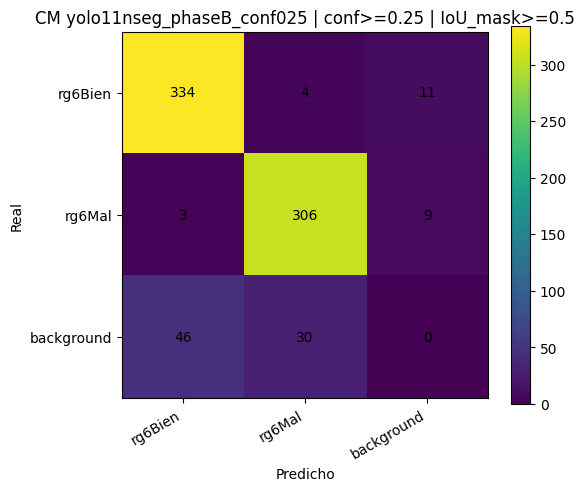

[yolo11nseg_phaseB_conf025] precisión por clase: {'rg6Bien': 0.8721, 'rg6Mal': 0.9} | recall por clase: {'rg6Bien': 0.957, 'rg6Mal': 0.9623}
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


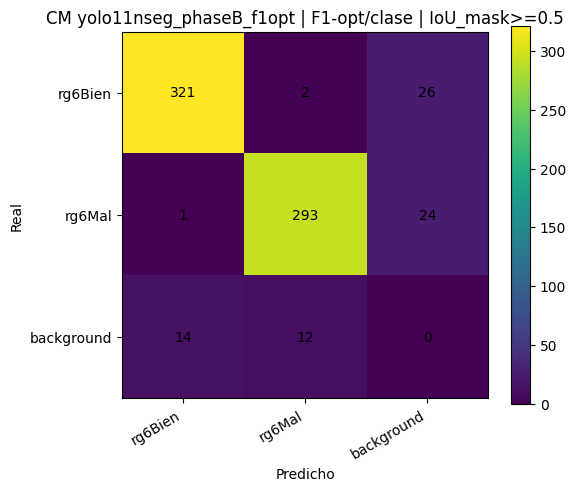

[yolo11nseg_phaseB_f1opt] precisión por clase: {'rg6Bien': 0.9554, 'rg6Mal': 0.9544} | recall por clase: {'rg6Bien': 0.9198, 'rg6Mal': 0.9214}


In [10]:
import matplotlib.pyplot as plt

def matriz_confusion(tag, pred_json, gt_json, out_dir, conf=0.25, conf_por_clase=None, iou_min=0.5):
    os.makedirs(out_dir, exist_ok=True)
    coco = COCO(gt_json)
    cats = sorted(coco.loadCats(coco.getCatIds()), key=lambda c: c["id"])
    idx_de = {c["id"]: i for i, c in enumerate(cats)}
    nombres = [c["name"] for c in cats]
    C = len(cats)
    umbral = {c["id"]: (conf_por_clase or {}).get(c["name"], conf) for c in cats}
    with open(pred_json) as f:
        preds = [p for p in json.load(f) if p["score"] >= umbral[p["category_id"]] and "segmentation" in p]
    por_img = {}
    for p in preds:
        por_img.setdefault(p["image_id"], []).append(p)

    cm = np.zeros((C + 1, C + 1), dtype=np.int64)
    for img_id in coco.getImgIds():
        anots = [a for a in coco.loadAnns(coco.getAnnIds(imgIds=[img_id])) if not a.get("iscrowd", 0)]
        reales = [(idx_de[a["category_id"]], coco.annToMask(a).astype(bool)) for a in anots]
        usados = set()
        for p in sorted(por_img.get(img_id, []), key=lambda p: -p["score"]):
            clase_p = idx_de[p["category_id"]]
            mascara_p = mask_util.decode(p["segmentation"]).astype(bool)
            mejor, mejor_iou = -1, 0.0
            for k, (_, mascara_r) in enumerate(reales):
                if k in usados:
                    continue
                inter = np.logical_and(mascara_p, mascara_r).sum()
                if inter == 0:
                    continue
                iou = inter / float(np.logical_or(mascara_p, mascara_r).sum())
                if iou > mejor_iou:
                    mejor_iou, mejor = iou, k
            if mejor >= 0 and mejor_iou >= iou_min:
                usados.add(mejor)
                cm[reales[mejor][0], clase_p] += 1
            else:
                cm[C, clase_p] += 1
        for k, (clase_r, _) in enumerate(reales):
            if k not in usados:
                cm[clase_r, C] += 1

    etiquetas = nombres + ["background"]
    np.savetxt(os.path.join(out_dir, "confusion_matrix.csv"), cm, fmt="%d", delimiter=",")
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm)
    ax.set_xticks(range(C + 1)); ax.set_yticks(range(C + 1))
    ax.set_xticklabels(etiquetas, rotation=30, ha="right"); ax.set_yticklabels(etiquetas)
    ax.set_xlabel("Predicho"); ax.set_ylabel("Real")
    ax.set_title(f"CM {tag} | {'F1-opt/clase' if conf_por_clase else f'conf>={conf}'} | IoU_mask>={iou_min}")
    for i in range(C + 1):
        for j in range(C + 1):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")
    fig.colorbar(im, ax=ax)
    fig.tight_layout()
    fig.savefig(os.path.join(out_dir, "confusion_matrix.png"), dpi=200)
    plt.show()

    precision = {nombres[k]: round(float(cm[k, k] / max(cm[:, k].sum(), 1)), 4) for k in range(C)}
    recall = {nombres[k]: round(float(cm[k, k] / max(cm[k, :].sum(), 1)), 4) for k in range(C)}
    with open(os.path.join(out_dir, "confusion_summary.json"), "w") as f:
        json.dump({"tag": tag, "conf": conf, "conf_por_clase": {c["name"]: umbral[c["id"]] for c in cats},
                   "conf_fuente": "umbral F1-óptimo de valid" if conf_por_clase else "conf único",
                   "iou_mask": iou_min, "labels": etiquetas, "cm": cm.tolist(),
                   "precision_por_clase": precision, "recall_por_clase": recall,
                   "pred_json": pred_json, "gt_json": gt_json}, f, indent=2, ensure_ascii=False)
    print(f"[{tag}] precisión por clase: {precision} | recall por clase: {recall}")

for modo, umbrales in (("conf025", None), ("f1opt", {k: v["conf"] for k, v in UMBRAL_F1.items()})):
    tag = f"yolo11nseg_phaseB_{modo}"
    matriz_confusion(tag, PRED_JSON, GT_JSON, os.path.join(REPORT_DIR, f"confusion_{tag}"), conf_por_clase=umbrales)

## 11) Registro de la sesión
Se guarda la semilla, la GPU y la fecha de la ejecución.

In [11]:
import datetime
with open(os.path.join(DRIVE_OUT, "sesion.json"), "w") as f:
    json.dump({"seed": SEED, "dataset": DATASET, "huella_datos": ORIGEN["huella"],
               "gpu": torch.cuda.get_device_name(0),
               "vram_total_gb": round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1),
               "fecha_utc": datetime.datetime.now(datetime.timezone.utc).isoformat()}, f, indent=2)

for raiz, _, archivos in os.walk(DRIVE_OUT):
    if "ckpt" in raiz:
        continue
    for a in sorted(archivos):
        ruta = os.path.join(raiz, a)
        print(f"  {os.path.getsize(ruta) / 2**20:8.1f} MB  {os.path.relpath(ruta, DRIVE_OUT)}")

       0.0 MB  TERMINADO.json
       5.8 MB  best.pt
       0.0 MB  run_manifest.json
       0.0 MB  sesion.json
       5.8 MB  yolo11nseg_best.pt
       0.0 MB  reportes/obj2_results_all_models.csv
       0.0 MB  reportes/obj2_results_all_models.json
       0.0 MB  reportes/obj2_yolo11nseg_phaseB_per_class_ap.json
       0.0 MB  reportes/umbral_operativo_f1_valid.json
       0.0 MB  reportes/confusion_yolo11nseg_phaseB_conf025/confusion_matrix.csv
       0.1 MB  reportes/confusion_yolo11nseg_phaseB_conf025/confusion_matrix.png
       0.0 MB  reportes/confusion_yolo11nseg_phaseB_conf025/confusion_summary.json
       0.0 MB  reportes/confusion_yolo11nseg_phaseB_f1opt/confusion_matrix.csv
       0.1 MB  reportes/confusion_yolo11nseg_phaseB_f1opt/confusion_matrix.png
       0.0 MB  reportes/confusion_yolo11nseg_phaseB_f1opt/confusion_summary.json
       0.1 MB  artefactos/entrenamiento/BoxF1_curve.png
       0.1 MB  artefactos/entrenamiento/BoxPR_curve.png
       0.1 MB  artefactos/entren